In [1]:
import rbfopt
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="Signature .* for <class 'numpy.longdouble'> does not match any known type")
import csv

/home/albertlee/miniconda3/envs/rbfopt/lib/python3.13/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [427]:
def load_grid(filename="ackley_30x30.csv"):
    """
    Load grid data from CSV.
    Expected CSV columns: "x", "y", "Objective", among others.
    Returns a dictionary mapping (x, y) tuples to the objective value.
    """
    grid_data = {}
    with open(filename, "r") as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                # Convert x and y values to integers
                x_val = int(row["x"])
                y_val = int(row["y"])
                # Convert objective value to float
                obj_val = float(row["z_norm"])
                grid_data[(x_val, y_val)] = obj_val
            except Exception as e:
                # Skip rows with conversion issues
                continue
    return grid_data
# Load the data from grid.csv
grid_data = load_grid()

# Determine grid bounds from the keys of grid_data
xs = [pt[0] for pt in grid_data.keys()]
ys = [pt[1] for pt in grid_data.keys()]
min_x, max_x = min(xs), max(xs)
min_y, max_y = min(ys), max(ys)
print("Grid bounds:")
print("x in [{}, {}]".format(min_x, max_x))
print("y in [{}, {}]".format(min_y, max_y))

Grid bounds:
x in [0, 30]
y in [0, 30]


In [428]:
# Load the data from grid.csv
grid_data = load_grid()

# PENALTY = 1e5  # adjust this penalty as appropriate
PENALTY = np.inf # use infinity as penalty for infeasible points
# PENALTY = np.nan  # use NaN as penalty for infeasible points
# PENALTY = None  # use None as penalty for infeasible points

def obj_funct(x):
    """
    Given a candidate point x (a list or 1-D numpy array with 2 elements),
    this function rounds x to the nearest integers and returns the objective value
    if the point exists in grid_data and is feasible (i.e. y <= x).
    Otherwise, returns a penalty value.
    """
    # Round the candidate coordinates to nearest integers
    x_int = int(round(x[0]))
    y_int = int(round(x[1]))
        
    # If the point exists in the grid, return its objective value.
    if (x_int, y_int) in grid_data:
        return grid_data[(x_int, y_int)]
    else:
        # If the point is not in the grid, return the penalty.
        return PENALTY

In [429]:
test_point = [27,27]
value = obj_funct(test_point)
print(f"For point {test_point} the objective value is {value}")

For point [27, 27] the objective value is 0.773037805238594


In [435]:
import time
start_time = time.time()
# Set up the black-box for a 2D problem with integer variables.
# We use the determined bounds and mark both variables as integer ("I").
black_box = rbfopt.RbfoptUserBlackBox(
    2,                   # number of variables
    np.array([0, 0]),    # lower bounds for x and y
    np.array([30, 30]),    # upper bounds for x and y
    np.array(["I", "I"]),# both variables are integers
    obj_funct
)

# Configure optimization settings.
settings = rbfopt.RbfoptSettings(
    max_evaluations=10,  # maximum number of evaluations
    minlp_solver_path='/home/albertlee/ampl.linux-intel64/bonmin',
    nlp_solver_path='/home/albertlee/ampl.linux-intel64/ipopt',
    algorithm='MSRSM',   # optimization algorithm variant
    rbf='auto',           # allow automatic RBF selection
    global_search_method = 'solver',  # options = ['sampling', 'genetic', 'solver']
)

# Create the optimization algorithm instance.
alg = rbfopt.RbfoptAlgorithm(settings, black_box)

# Run the optimization.
best_val, best_point, itercount, evalcount, fast_evalcount = alg.optimize()
end_time = time.time()
print(f"\nTotal optimization time: {end_time - start_time:.2f} seconds")

print("Optimization completed.")
print("Best objective value found:", best_val)
print("At lattice point (rounded):", [int(round(v)) for v in best_point])
print("Iterations:", itercount, "Function evaluations:", evalcount)

  Iter  Cycle  Action             Objective value      Time      Gap
  ----  -----  ------             ---------------      ----      ---
     0      0  Initialization            0.836216      0.01   100.00  
     0      0  Initialization            0.788379      0.02   100.00  
     0      0  Initialization            0.000000      0.02   100.00 *
     0      0  GlobalStep                0.887378      0.19   100.00  
     1      0  GlobalStep                0.887378      0.45   100.00  
     2      0  GlobalStep                0.165312      0.69   100.00  
     3      0  GlobalStep                0.185130      0.93   100.00  
     4      0  GlobalStep                0.165312      1.29   100.00  
     5      0  AdjLocalStep              0.165312      2.02   100.00  
     6      0  RefinementStep            0.165312      2.03   100.00  
Summary: iters   7 evals  10 noisy_evals   0 cycles   0 opt_time    2.03 tot_time    2.02 obj         0.000000 gap 100.00
Trajectory: 
Iter   0 Obj     

In [439]:
import math
from typing import Dict, Iterable, List, Optional, Tuple
import time
import pandas as pd

Point = Tuple[int, int]


# =============================
# CSV -> (x,y) -> value mapping
# =============================
def load_grid_from_csv(
    csv_path: str,
    value_col: str = "z_norm",
    x_col: str = "x",
    y_col: str = "y",
) -> Dict[Point, float]:
    df = pd.read_csv(csv_path)
    needed = {x_col, y_col, value_col}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"CSV missing required columns: {sorted(missing)}")

    grid: Dict[Point, float] = {}
    for _, r in df.iterrows():
        x = int(r[x_col])
        y = int(r[y_col])
        z = float(r[value_col])
        grid[(x, y)] = z

    if not grid:
        raise ValueError("CSV parsed but produced an empty grid.")

    return grid


# =============================
# Neighbor search utilities
# =============================
def get_neighbors(
    I: Iterable[int],
    J: Iterable[int],
    x: int,
    y: int,
    forbid_x: Optional[int] = 3,
    include_self: bool = False,
) -> List[Point]:
    directions = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),  (0, 0),  (0, 1),
        (1, -1),  (1, 0),  (1, 1),
    ]
    if not include_self:
        directions = [(dx, dy) for (dx, dy) in directions if not (dx == 0 and dy == 0)]

    I_set = set(I)
    J_set = set(J)

    nbrs: List[Point] = []
    for dx, dy in directions:
        nx, ny = x + dx, y + dy
        if nx in I_set and ny in J_set:
            if forbid_x is not None and nx == forbid_x:
                continue
            nbrs.append((nx, ny))
    return nbrs


def _step_length(p: Point, q: Point) -> float:
    return math.hypot(q[0] - p[0], q[1] - p[1])


def pick_best_neighbor(
    current: Point,
    candidates: List[Point],
    f: Dict[Point, float],
    prefer_farther_on_tie: bool = True,
) -> Point:
    """
    Argmin over candidates by f(q).
    Tie-breaks:
      1) prefer farther step (diagonal) if enabled
      2) lexicographic for determinism
    """
    best = candidates[0]
    best_val = f[best]

    for q in candidates[1:]:
        v = f[q]
        if v < best_val:
            best, best_val = q, v
        elif v == best_val:
            if prefer_farther_on_tie:
                dq = _step_length(current, q)
                db = _step_length(current, best)
                if dq > db:
                    best, best_val = q, v
                elif dq == db and q < best:
                    best, best_val = q, v
            else:
                if q < best:
                    best, best_val = q, v

    return best


# =============================
# LDSDA-style line search
# (strict improvement, stop on first worse/non-improving)
# =============================
def line_search_strict(
    start: Point,
    direction: Point,  # (dx,dy) in {-1,0,1}^2, not (0,0)
    f: Dict[Point, float],
    I_set: set,
    J_set: set,
    forbid_x: Optional[int] = 3,
    eps: float = 0.0,
    max_steps: int = 10_000,
) -> Tuple[Point, List[Point]]:
    dx, dy = direction
    if dx == 0 and dy == 0:
        return start, [start]

    curr = start
    curr_val = f[curr]
    segment = [curr]

    for _ in range(max_steps):
        nxt = (curr[0] + dx, curr[1] + dy)

        # Stop if out of bounds / forbidden / missing
        if nxt[0] not in I_set or nxt[1] not in J_set:
            break
        if forbid_x is not None and nxt[0] == forbid_x:
            break
        if nxt not in f:
            break

        nxt_val = f[nxt]

        # Strict improvement only
        if nxt_val < curr_val - eps:
            curr = nxt
            curr_val = nxt_val
            segment.append(curr)
        else:
            # worse/non-improving => stop, keep best found (curr)
            break

    return curr, segment


# =============================
# Main LD-SDA loop:
# neighbor search -> line search -> neighbor search -> ...
# stop when no improving neighbor
# =============================
def ld_sda(
    I: Iterable[int],
    J: Iterable[int],
    initial_point: Point,
    grid_values: Dict[Point, float],
    forbid_x: Optional[int] = 3,
    eps: float = 0.0,
    prefer_farther_on_tie: bool = True,
    max_iters: int = 10_000,
    max_line_steps: int = 10_000,
    verbose: bool = True,
    trace: bool = True,  # NEW: store structured trace for post-analysis
) -> Dict[str, object]:
    I_set = set(I)
    J_set = set(J)

    if initial_point not in grid_values:
        raise ValueError(f"Initial point {initial_point} not found in the grid values.")
    if initial_point[0] not in I_set or initial_point[1] not in J_set:
        raise ValueError(f"Initial point {initial_point} not inside I×J domain.")
    if forbid_x is not None and initial_point[0] == forbid_x:
        raise ValueError(f"Initial point {initial_point} violates forbid_x={forbid_x}.")

    current = initial_point
    path: List[Point] = [current]
    line_segments: List[List[Point]] = []
    neighbor_trace: List[dict] = []  # NEW

    if verbose:
        print(f"[init] point={current}, f={grid_values[current]:.6f}")

    for it in range(1, max_iters + 1):
        curr_val = grid_values[current]

        # --- Neighbor search ---
        nbrs = get_neighbors(
            I_set, J_set, current[0], current[1], forbid_x=forbid_x, include_self=False
        )
        nbrs = [p for p in nbrs if p in grid_values]
        if not nbrs:
            if verbose:
                print(f"[stop] iter={it}: no neighbors in grid.")
            break

        # NEW: show all neighbors and values
        if verbose:
            print(f"         neighbors ({len(nbrs)}):")
            for p in nbrs:
                print(f"           {p} -> f={grid_values[p]:.6f}")

        best_nbr = pick_best_neighbor(
            current, nbrs, grid_values, prefer_farther_on_tie=prefer_farther_on_tie
        )
        best_val = grid_values[best_nbr]

        # Termination: no improving neighbor
        if best_val >= curr_val - eps:
            if verbose:
                print(
                    f"[stop] iter={it}: surrounded "
                    f"(best neighbor f={best_val:.6f} >= current f={curr_val:.6f})."
                )
            break

        # Direction from best neighbor
        direction = (best_nbr[0] - current[0], best_nbr[1] - current[1])

        # NEW: richer chosen-neighbor log
        if verbose:
            print(
                f"[iter {it}] current={current} f={curr_val:.6f}\n"
                f"         --> chosen neighbor={best_nbr} f={best_val:.6f} dir={direction}"
            )

        # NEW: store structured trace
        if trace:
            neighbor_trace.append(
                {
                    "iter": it,
                    "current": current,
                    "current_value": curr_val,
                    "neighbors": [(p, grid_values[p]) for p in nbrs],
                    "chosen_neighbor": best_nbr,
                    "chosen_value": best_val,
                    "direction": direction,
                }
            )

        # --- Line search along direction ---
        new_point, segment = line_search_strict(
            start=current,
            direction=direction,
            f=grid_values,
            I_set=I_set,
            J_set=J_set,
            forbid_x=forbid_x,
            eps=eps,
            max_steps=max_line_steps,
        )

        line_segments.append(segment)

        # append full line segment (avoid duplicate start)
        if len(segment) > 1:
            path.extend(segment[1:])

        # NEW: print full segment path and values
        if verbose:
            print(
                f"         line_search: len={len(segment)} "
                f"end={new_point} f_end={grid_values[new_point]:.6f}"
            )
            print("         segment:")
            for p in segment:
                print(f"           {p} -> f={grid_values[p]:.6f}")

        # If line search didn't move, something contradicts “best_nbr improves”.
        # Fallback to moving to best_nbr.
        if new_point == current:
            if verbose:
                print("         (fallback) line search didn't move; stepping to best_nbr.")
            current = best_nbr
            path.append(current)
        else:
            current = new_point

    return {
        "best_point": current,
        "best_value": grid_values[current],
        "path": path,
        "line_segments": line_segments,
        "neighbor_trace": neighbor_trace,  # NEW
        "iterations": len(line_segments),
    }


def main(
    I: Iterable[int],
    J: Iterable[int],
    initial_point: Point,
    csv_path: str,
    forbid_x: Optional[int] = 3,
    eps: float = 0.0,
    prefer_farther_on_tie: bool = True,
    max_iters: int = 10_000,
    max_line_steps: int = 10_000,
    verbose: bool = True,
    trace: bool = True,
) -> Dict[str, object]:
    grid = load_grid_from_csv(csv_path)
    return ld_sda(
        I=I,
        J=J,
        initial_point=initial_point,
        grid_values=grid,
        forbid_x=forbid_x,
        eps=eps,
        prefer_farther_on_tie=prefer_farther_on_tie,
        max_iters=max_iters,
        max_line_steps=max_line_steps,
        verbose=verbose,
        trace=trace,
    )


if __name__ == "__main__":
    I = range(0, 31)
    J = range(0, 31)

    # Example start
    initial_point = (1, 1)

    start = time.time()
    res = main(
        I=I,
        J=J,
        initial_point=initial_point,
        csv_path="ackley_30x30.csv",
        forbid_x=None,          # set to 3 to forbid x=3, or None to allow all x
        eps=0.0,
        prefer_farther_on_tie=True,
        max_iters=10_000,
        max_line_steps=10_000,
        verbose=True,
        trace=True,
    )
    end = time.time()
    print(f"\nTotal time: {end - start:.2f} seconds")

    print("\n=== RESULT ===")
    print("Best point:", res["best_point"])
    print("Best value:", res["best_value"])
    print("Iterations:", res["iterations"])
    print("Path length:", len(res["path"]))
    print("Path (first 30):", res["path"][:30])

    # Optional: peek at stored trace for iter 1
    if res["neighbor_trace"]:
        t0 = res["neighbor_trace"][0]
        print("\n=== TRACE (iter 1) ===")
        print("current:", t0["current"], "f=", t0["current_value"])
        print("chosen:", t0["chosen_neighbor"], "f=", t0["chosen_value"], "dir=", t0["direction"])
        print("neighbors:")
        for p, v in t0["neighbors"]:
            print(" ", p, "->", v)


[init] point=(1, 1), f=1.000000
         neighbors (8):
           (0, 0) -> f=0.887378
           (0, 1) -> f=0.970851
           (0, 2) -> f=0.953757
           (1, 0) -> f=0.970851
           (1, 2) -> f=0.981641
           (2, 0) -> f=0.953757
           (2, 1) -> f=0.981641
           (2, 2) -> f=0.961943
[iter 1] current=(1, 1) f=1.000000
         --> chosen neighbor=(0, 0) f=0.887378 dir=(-1, -1)
         line_search: len=2 end=(0, 0) f_end=0.887378
         segment:
           (1, 1) -> f=1.000000
           (0, 0) -> f=0.887378
         neighbors (3):
           (0, 1) -> f=0.970851
           (1, 0) -> f=0.970851
           (1, 1) -> f=1.000000
[stop] iter=2: surrounded (best neighbor f=0.970851 >= current f=0.887378).

Total time: 0.03 seconds

=== RESULT ===
Best point: (0, 0)
Best value: 0.8873775041748184
Iterations: 1
Path length: 2
Path (first 30): [(1, 1), (0, 0)]

=== TRACE (iter 1) ===
current: (1, 1) f= 0.9999999999999998
chosen: (0, 0) f= 0.8873775041748184 dir= (-

/home/albertlee/miniconda3/envs/rbfopt/lib/python3.13/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


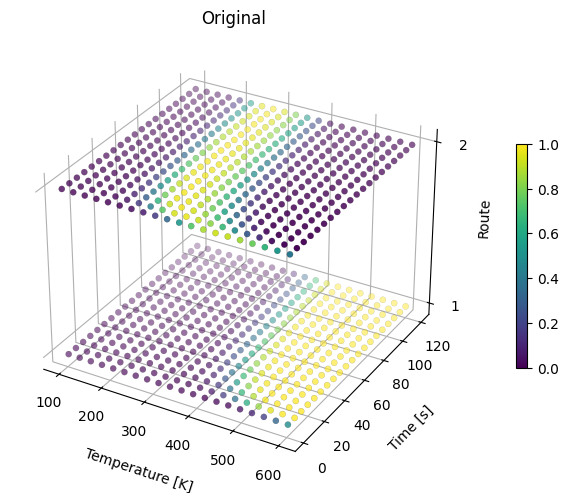

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# -----------------------------
# Kinetic Model (same as notebook)
# -----------------------------
R = 8.314  # J/mol·K

params_r1 = {"A1": 5e3, "E1": 42000, "A2": 3e3, "E2": 35000}
params_r2 = {"A3": 3e3, "E3": 25000, "A4": 3e3, "E4": 40000}

def initial_conditions():
    # [A], [B], [C]  OR  [A], [C], [D]
    return [1.0, 0.0, 0.0]

def ode_ruta1(t, y, T):
    A, B, C = y
    k1 = params_r1["A1"] * np.exp(-params_r1["E1"] / (R * T))
    k2 = params_r1["A2"] * np.exp(-params_r1["E2"] / (R * T))
    dA_dt = -k1 * A
    dB_dt = k1 * A - k2 * B
    dC_dt = k2 * B
    return [dA_dt, dB_dt, dC_dt]

def ode_ruta2(t, y, T):
    A, C, D = y
    k3 = params_r2["A3"] * np.exp(-params_r2["E3"] / (R * T))
    k4 = params_r2["A4"] * np.exp(-params_r2["E4"] / (R * T))
    dA_dt = -k3 * A
    dC_dt = k3 * A - k4 * C
    dD_dt = k4 * C
    return [dA_dt, dC_dt, dD_dt]

def evaluate_C_from_indices(t_idx, tau_idx, ruta_idx, T_range, Tau_range):
    T = T_range[t_idx]
    Tau = Tau_range[tau_idx]
    Ruta = ruta_idx + 1
    if Ruta == 1:
        sol = solve_ivp(
            ode_ruta1, [0, Tau], initial_conditions(),
            args=(T,), method="LSODA"
        )
        return sol.y[2, -1]  # C
    else:
        sol = solve_ivp(
            ode_ruta2, [0, Tau], initial_conditions(),
            args=(T,), method="LSODA"
        )
        return sol.y[1, -1]  # C (second state in route 2)

# -----------------------------
# Generate discrete data (same grid sizes/ranges)
# -----------------------------
n_T = 20     # Temperature
n_Tau = 20   # Time
n_Ruta = 2   # Route

T_range = np.linspace(100, 600, n_T)
Tau_range = np.linspace(1, 120, n_Tau)

T_idx, Tau_idx, Ruta_idx, C_final = [], [], [], []

for i in range(n_T):
    for j in range(n_Tau):
        for r in range(n_Ruta):
            C_val = evaluate_C_from_indices(i, j, r, T_range, Tau_range)
            T_idx.append(i)
            Tau_idx.append(j)
            Ruta_idx.append(r)
            C_final.append(C_val)

def recover_T(i): return T_range[i]
def recover_Tau(j): return Tau_range[j]
def recover_Ruta(k): return k + 1

T_real = np.array([recover_T(i) for i in T_idx])
Tau_real = np.array([recover_Tau(j) for j in Tau_idx])
Ruta_real = np.array([recover_Ruta(k) for k in Ruta_idx])
Z_vals = np.array(C_final, dtype=float)

# -----------------------------
# Plot: "Original" (same styling)
# -----------------------------
fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(111, projection="3d")

sc1 = ax1.scatter(
    T_real, Tau_real, Ruta_real,
    c=Z_vals, cmap="viridis",
    s=20, edgecolors="black", linewidths=0.1
)

ax1.set_title("Original")
ax1.set_xlabel("Temperature [K]", labelpad=10)
ax1.set_ylabel("Time [s]", labelpad=10)
ax1.set_zlabel("Route", labelpad=2)
ax1.set_zticks([1, 2])

# Transparent panes (same as notebook)
ax1.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
ax1.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
ax1.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))

fig.colorbar(sc1, ax=ax1, pad=0.05, shrink=0.5)
plt.tight_layout()
plt.show()